# Patient-Specific Game-Based Transfer (PSGT) for Parkinson's Disease Severity Prediction
**Base paper:** Xue Z., Lu H., Zhang T., Little M.A. (2024), *Artificial Intelligence in Medicine* 150, 102810
**Students:** Harshine S S (127176035), Sahana S (127176097)  |  **Guide:** Brindha G R, SoC

**Notebook map**
1. Setup, data loading and preprocessing
2. Evaluation helpers (MAE, MSE, RMSE, R², Volatility)
3. Baselines: single models (SVR, XGBoost, RF) and combined models (FS-RF, Boruta-XGBoost, ARD-GPR)
4. Transfer-learning models: ST-All, ST, FDAMF, PTL, TrAdaBoost
5. **PSGT** (subject transfer + Shapley instance transfer)
6. Run all 42 target patients, motor- and total-UPDRS
7. Comparison against the paper's Table 3
8. Graphs, Wilcoxon significance test, sensitivity analysis
9. **Novelty:** clinical severity category (Normal / Mild / Moderate / Severe) from the predicted UPDRS
10. **New test case prediction** (unseen recording / new patient)
11. Save all outputs

> **Runtime:** the full run takes roughly 20-40 min on a free Colab CPU. Set `N_TARGETS` in the config cell to a small number (e.g. 5) for a quick test run.

## 1. Setup, data loading and preprocessing

In [1]:
import os, time, warnings, pickle, itertools
from math import factorial
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, binom
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as CK
from sklearn.metrics import (r2_score, accuracy_score, f1_score, confusion_matrix,
                             cohen_kappa_score, ConfusionMatrixDisplay)
from xgboost import XGBRegressor
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

In [2]:
# ----------------------------- CONFIG --------------------------------------
SEED       = 42
N_TARGETS  = int(os.environ.get('N_TARGETS', 42))   # 42 = all patients (paper protocol). Use 5 for a quick test.
N_JOBS     = -1                                      # use all CPU cores
SPLIT      = (6, 2, 2)                               # train : validation : test  (paper, Table 2)
K          = 5                                       # transferred subjects (paper, Table 2)
# Paper Table 2: motor -> 30 trees, L=5 ; total -> 50 trees, L=6 ; depth 50
PARAMS = {'motor_UPDRS': dict(ntree=30, L=5), 'total_UPDRS': dict(ntree=50, L=6)}
DEPTH      = 50
N_COALITIONS = 40      # Monte-Carlo coalitions per source subject for the simplified instance Shapley
RUN_SENSITIVITY = True # set False to skip section 8.3 (saves time)
SENS_PATIENTS   = 10   # number of target patients used in the sensitivity analysis
OUT_DIR = 'outputs'; os.makedirs(OUT_DIR, exist_ok=True)

In [3]:
# ---- locate / upload the dataset ----
CANDIDATES = [os.environ.get('DATA_PATH',''), 'Parkinsons_Telemonitoring_RAW_DATA.xlsx',
              '/content/Parkinsons_Telemonitoring_RAW_DATA.xlsx',
              '/content/drive/MyDrive/Parkinsons_Telemonitoring_RAW_DATA.xlsx']
DATA_PATH = next((p for p in CANDIDATES if p and os.path.exists(p)), None)
if DATA_PATH is None:
    from google.colab import files          # Colab only: pick Parkinsons_Telemonitoring_RAW_DATA.xlsx
    up = files.upload(); DATA_PATH = list(up.keys())[0]
raw = pd.read_excel(DATA_PATH)
print('Loaded:', DATA_PATH, raw.shape)
raw.head()

Loaded: Parkinsons_Telemonitoring_RAW_DATA.xlsx (5875, 22)


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361


In [4]:
# ---- preprocessing ----
df = raw.copy()
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={'subject#': 'subject'})
print('Missing values :', int(df.isna().sum().sum()))
print('Duplicate rows :', int(df.duplicated().sum()))
df = df.dropna().drop_duplicates().reset_index(drop=True)

TARGETS = ['motor_UPDRS', 'total_UPDRS']
VOICE   = [c for c in df.columns if c not in ['subject', 'age', 'sex', 'test_time'] + TARGETS]   # 16 dysphonia measures
FEATS   = ['age', 'sex'] + VOICE        # 16 voice features + age + gender (paper Sec. 4.1)  -> 18 inputs
SUBJECTS = sorted(df['subject'].unique())
DATA = {s: df[df['subject'] == s].reset_index(drop=True) for s in SUBJECTS}

print(f'Patients: {len(SUBJECTS)} | Recordings: {len(df)} | Voice features: {len(VOICE)} | Model inputs: {len(FEATS)}')
print(f'Male: {(df.groupby("subject").sex.first()==0).sum()}  Female: {(df.groupby("subject").sex.first()==1).sum()} | mean age: {df.groupby("subject").age.first().mean():.1f}')
print(f'Recordings per patient: mean {df.groupby("subject").size().mean():.0f} (min {df.groupby("subject").size().min()}, max {df.groupby("subject").size().max()})')
print(df[TARGETS].describe().loc[['min','mean','max']].round(2))

Missing values : 0
Duplicate rows : 0
Patients: 42 | Recordings: 5875 | Voice features: 16 | Model inputs: 18
Male: 28  Female: 14 | mean age: 64.4
Recordings per patient: mean 140 (min 101, max 168)
      motor_UPDRS  total_UPDRS
min          5.04         7.00
mean        21.30        29.02
max         39.51        54.99


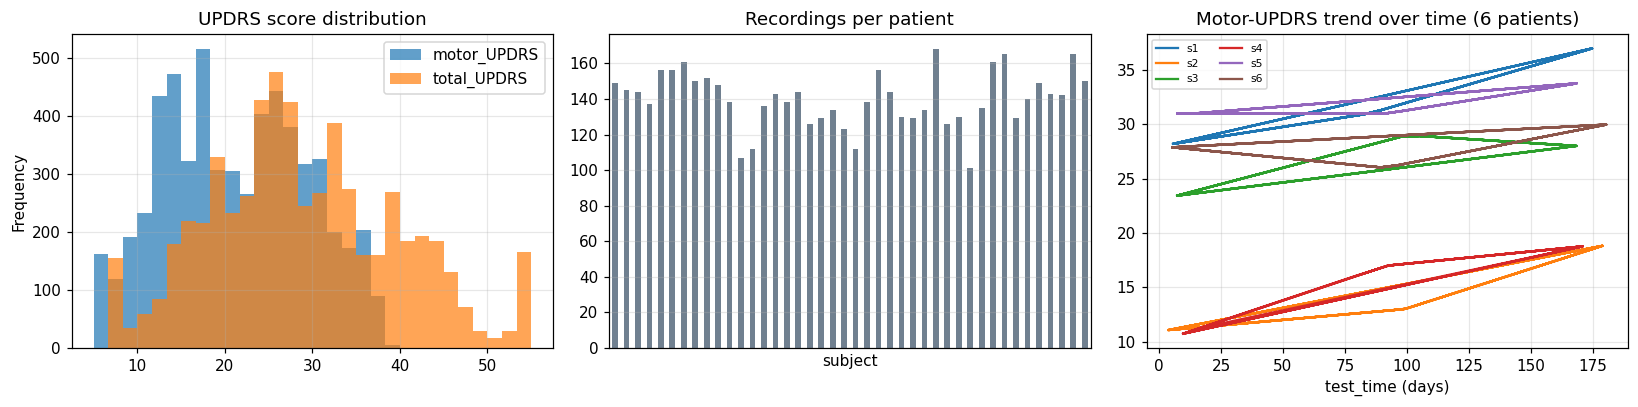

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df[TARGETS].plot.hist(bins=30, alpha=.7, ax=ax[0]); ax[0].set_title('UPDRS score distribution')
df.groupby('subject').size().plot.bar(ax=ax[1], color='slategray'); ax[1].set_title('Recordings per patient'); ax[1].set_xticks([])
for s in SUBJECTS[:6]: ax[2].plot(DATA[s].test_time, DATA[s].motor_UPDRS, label=f's{s}')
ax[2].set_title('Motor-UPDRS trend over time (6 patients)'); ax[2].set_xlabel('test_time (days)'); ax[2].legend(ncol=2, fontsize=7)
plt.tight_layout(); plt.show()

## 2. Evaluation helpers
Metrics follow paper Eqs. 16-18 (MAE, RMSE, Volatility); MSE and R² are added as in the review PPT. Volatility = mean absolute deviation of the error from its mean.

In [5]:
def metrics(y, p):
    v = y - p
    return dict(MAE=float(np.mean(np.abs(v))), MSE=float(np.mean(v**2)), RMSE=float(np.sqrt(np.mean(v**2))),
                R2=float(r2_score(y, p)) if len(y) > 1 else np.nan, Vol=float(np.mean(np.abs(v - v.mean()))))

def make_rf(n, seed=SEED): return RandomForestRegressor(n_estimators=n, max_depth=DEPTH, random_state=seed, n_jobs=1)

def split_idx(s, seed=SEED, ratio=SPLIT):
    """Random (non-chronological) train/val/test split of a patient's recordings, default 6:2:2 (paper Sec. 4.3)."""
    n = len(DATA[s]); idx = np.arange(n); tr_f, va_f, te_f = [r/sum(ratio) for r in ratio]
    tr, rest = train_test_split(idx, train_size=tr_f, random_state=seed)
    va, te = train_test_split(rest, train_size=va_f/(va_f+te_f), random_state=seed)
    return tr, va, te

def patient_arrays(t, target, ratio=SPLIT, seed=SEED):
    d = DATA[t]; tr, va, te = split_idx(t, seed, ratio)
    X, y = d[FEATS].values, d[target].values
    return X[tr], y[tr], X[va], y[va], X[te], y[te]

def pooled_sources(t, target):
    """All recordings of every OTHER patient (the source domain)."""
    oth = [s for s in SUBJECTS if s != t]
    return (np.vstack([DATA[s][FEATS].values for s in oth]), np.concatenate([DATA[s][target].values for s in oth]))

def train_source_models(target):
    """One RF per patient trained on all his/her recordings (paper Eq. 4). Re-used for every target patient."""
    nt = PARAMS[target]['ntree']
    return {s: make_rf(nt).fit(DATA[s][FEATS].values, DATA[s][target].values) for s in SUBJECTS}

## 3. Baseline models
**Important finding while matching the paper:** Sec. 5.1 of the paper states that the *single* models (SVR, XGBoost, RF) directly use **all** other patients' data together with the target's training set (no subject filtering). Re-creating that protocol reproduces the paper's SVR value (6.66 MAE) almost exactly, so single and feature-selection (combined) models here are trained on `target-train ∪ all source patients`. ARD-GPR is exact O(n³), so it is fitted on the target patient's training set only.

In [6]:
def boruta_select(X, y, n_iter=10, ntree=30, seed=SEED, min_hits=7, max_rows=1200):
    """Lightweight Boruta (shadow-feature test with RF importance). Avoids the boruta_py / numpy-2 incompatibility."""
    rng = np.random.RandomState(seed)
    if len(y) > max_rows:
        sub = rng.choice(len(y), max_rows, replace=False); X, y = X[sub], y[sub]
    p = X.shape[1]; hits = np.zeros(p)
    for it in range(n_iter):
        Xs = np.apply_along_axis(rng.permutation, 0, X)
        m = RandomForestRegressor(ntree, max_depth=12, random_state=seed+it, n_jobs=1).fit(np.hstack([X, Xs]), y)
        imp = m.feature_importances_; hits += imp[:p] > imp[p:].max()
    sel = np.where(hits >= min_hits)[0]
    return sel if len(sel) else np.argsort(-hits)[:5]

def rf_importance_select(X, y, ntree=30, seed=SEED, max_rows=1200):
    """FS-RF: keep features whose RF importance is above the median."""
    rng = np.random.RandomState(seed)
    if len(y) > max_rows:
        sub = rng.choice(len(y), max_rows, replace=False); X, y = X[sub], y[sub]
    imp = RandomForestRegressor(ntree, max_depth=12, random_state=seed, n_jobs=1).fit(X, y).feature_importances_
    return np.where(imp >= np.median(imp))[0]

def run_baselines(Xtr, ytr, Xte, yte, Xs, ys, ntree):
    Xp, yp = np.vstack([Xtr, Xs]), np.concatenate([ytr, ys])          # pooled training set
    out = {}
    out['SVR']     = SVR().fit(Xp, yp).predict(Xte)                    # default, un-scaled (matches paper's behaviour)
    out['XGBoost'] = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, verbosity=0, n_jobs=1, random_state=SEED).fit(Xp, yp).predict(Xte)
    out['RF']      = make_rf(ntree).fit(Xp, yp).predict(Xte)
    fs = rf_importance_select(Xp, yp);  out['FS-RF'] = make_rf(ntree).fit(Xp[:, fs], yp).predict(Xte[:, fs])
    bs = boruta_select(Xp, yp);         out['Boruta-XGBoost'] = XGBRegressor(n_estimators=100, max_depth=6, verbosity=0, n_jobs=1, random_state=SEED).fit(Xp[:, bs], yp).predict(Xte[:, bs])
    # ARD-GPR on target-train only (anisotropic RBF = Automatic Relevance Determination)
    sc = StandardScaler().fit(Xtr)
    kern = CK(1.0) * RBF(length_scale=np.ones(Xtr.shape[1]), length_scale_bounds=(1e-2, 1e3)) + WhiteKernel(0.1)
    gpr = GaussianProcessRegressor(kern, normalize_y=True, n_restarts_optimizer=0, random_state=SEED).fit(sc.transform(Xtr), ytr)
    out['ARD-GPR'] = gpr.predict(sc.transform(Xte))
    out['RF (target-only)'] = make_rf(ntree).fit(Xtr, ytr).predict(Xte)   # extra reference: no transfer at all
    return out

## 4. Transfer-learning comparison models
* **ST-All** - add every source patient's data to the target training set
* **ST** - subject transfer only: add *all* instances of the top-k most similar patients
* **FDAMF** (Ji et al. 2018) - filter dissimilar source patients, fuse the remaining source models (+ target model) weighted by validation error
* **PTL** (Yoon & Li 2019) - positive transfer: keep a source patient only if it lowers the target validation error
* **TrAdaBoost** (Dai et al. 2007) - TrAdaBoost.R2-style boosting that down-weights misleading source instances

FDAMF / PTL / TrAdaBoost are re-implementations from the descriptions in the papers (no official code), so small numeric differences from the base paper's reported values are expected.

In [7]:
def rank_sources(t, SM, Xva, yva):
    others = [s for s in SUBJECTS if s != t]
    mae = {s: float(np.mean(np.abs(SM[s].predict(Xva) - yva))) for s in others}
    return sorted(others, key=lambda s: mae[s]), mae

def tradaboost_r2(Xs, ys, Xt, yt, n_est=10, depth=10, seed=SEED):
    n, m = len(ys), len(yt)
    X, y = np.vstack([Xs, Xt]), np.concatenate([ys, yt])
    w = np.ones(n + m) / (n + m)
    beta_s = 1.0 / (1.0 + np.sqrt(2.0 * np.log(n) / n_est))
    models, betas = [], []
    for i in range(n_est):
        w = w / w.sum()
        mdl = DecisionTreeRegressor(max_depth=depth, random_state=seed+i).fit(X, y, sample_weight=w)
        err = np.abs(mdl.predict(X) - y); err = err / (err.max() + 1e-12)
        eps = np.sum(w[n:] * err[n:]) / w[n:].sum()
        eps = min(max(eps, 1e-6), 0.49); beta_t = eps / (1 - eps)
        w[:n] *= beta_s ** err[:n]            # shrink source instances that are predicted badly
        w[n:] *= beta_t ** (-err[n:])         # boost hard target instances
        models.append(mdl); betas.append(beta_t)
    half = slice(n_est // 2, n_est)
    ws = np.log(1.0 / np.array(betas[half]))
    return lambda Xq: np.average([m_.predict(Xq) for m_ in models[half]], axis=0, weights=ws)

def run_transfer_baselines(t, target, SM, ntree, Xtr, ytr, Xva, yva, Xte, ranking, mae):
    out = {}
    Xall = np.vstack([DATA[s][FEATS].values for s in SUBJECTS if s != t]); yall = np.concatenate([DATA[s][target].values for s in SUBJECTS if s != t])
    out['ST_All'] = make_rf(ntree).fit(np.vstack([Xtr, Xall]), np.concatenate([ytr, yall])).predict(Xte)
    top = ranking[:K]
    Xk = np.vstack([DATA[s][FEATS].values for s in top]); yk = np.concatenate([DATA[s][target].values for s in top])
    out['ST'] = make_rf(ntree).fit(np.vstack([Xtr, Xk]), np.concatenate([ytr, yk])).predict(Xte)
    # FDAMF: filter (keep better half of sources) and fuse models by inverse validation error
    keep = ranking[:len(ranking)//2]
    tgt_model = make_rf(ntree).fit(Xtr, ytr); tgt_err = float(np.mean(np.abs(tgt_model.predict(Xva) - yva)))
    preds = [SM[s].predict(Xte) for s in keep] + [tgt_model.predict(Xte)]
    wts = np.array([1.0 / mae[s] for s in keep] + [1.0 / tgt_err]); out['FDAMF'] = np.average(preds, axis=0, weights=wts)
    # PTL: greedily accept a source only if it reduces target validation error (positive transfer)
    cur_X, cur_y = Xtr, ytr
    best = float(np.mean(np.abs(make_rf(10).fit(cur_X, cur_y).predict(Xva) - yva)))
    for s in ranking[:10]:
        cX = np.vstack([cur_X, DATA[s][FEATS].values]); cy = np.concatenate([cur_y, DATA[s][target].values])
        e = float(np.mean(np.abs(make_rf(10).fit(cX, cy).predict(Xva) - yva)))
        if e < best: best, cur_X, cur_y = e, cX, cy
    out['PTL'] = make_rf(ntree).fit(cur_X, cur_y).predict(Xte)
    # TrAdaBoost
    out['TrAdaBoost'] = tradaboost_r2(Xall, yall, Xtr, ytr)(Xte)
    return out

## 5. PSGT - Patient-Specific Game-based Transfer
**Step 1 - Subject transfer (Eqs. 4-6):** one RF per source patient; the k = 5 patients with the lowest MAE on the target's validation set are chosen.
**Step 2.1 - Subject importance (Eqs. 7-11):** exact Shapley value over the 2⁵ coalitions of the 5 transferred patients; the payoff γ is the validation MAE of an RF trained on `target-train ∪ coalition`. Shapley values are mapped with `1 - sigmoid(φ)` and normalised, then give the number of instances taken from each patient (`Num_i = Ψ_i · N/L`).
**Step 2.2 - Instance contribution (Eqs. 12-14):** *simplified* Shapley value of every instance, estimated by Monte-Carlo sampling of coalitions inside each transferred patient. Instances with positive Shapley value (they raise the error) are removed (Fig. 4); the best `Num_i` are kept.
**Step 3 - Prediction:** the selected instances are merged with the target training set and a Random Forest predicts the UPDRS (Eqs. 2-3). The transfer size is capped at N/L (L = 5 motor, 6 total) to avoid negative transfer.

In [8]:
def psgt_predict(t, target, SM, ntree, L, k=K, ratio=SPLIT, n_coal=N_COALITIONS, inst_ntree=10, seed=SEED, return_details=False):
    rng = np.random.RandomState(seed + int(t))
    Xtr, ytr, Xva, yva, Xte, yte = patient_arrays(t, target, ratio, seed)
    ranking, mae = rank_sources(t, SM, Xva, yva); top = ranking[:k]                    # ---- Step 1: subject transfer

    def gamma(coal):                                                                   # payoff = validation MAE
        if len(coal) == 0: X, y = Xtr, ytr
        else:
            X = np.vstack([Xtr] + [DATA[s][FEATS].values for s in coal]); y = np.concatenate([ytr] + [DATA[s][target].values for s in coal])
        return float(np.mean(np.abs(make_rf(10, seed).fit(X, y).predict(Xva) - yva)))
    g = {C: gamma([top[i] for i in C]) for r in range(k + 1) for C in combinations(range(k), r)}

    phi = np.zeros(k)                                                                  # ---- Step 2.1: exact subject Shapley (Eq. 7-8)
    for i in range(k):
        rest = [j for j in range(k) if j != i]
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for C in combinations(rest, r):
                phi[i] += w * (g[tuple(sorted(C + (i,)))] - g[C])
    phi_pos = 1.0 - 1.0 / (1.0 + np.exp(-phi))                                         # Eq. 9
    psi = phi_pos / phi_pos.sum()                                                      # Eq. 10
    N = len(ytr); cap = int(N // L)                                                    # transfer cap N/L (Fig. 4)
    nums = np.maximum(1, np.round(psi * cap).astype(int))                              # Eq. 11 (scaled to the cap)

    base = g[()]; selX, selY = [], []                                                  # ---- Step 2.2: simplified instance Shapley (Eq. 14)
    for i, s in enumerate(top):
        Xs, ys = DATA[s][FEATS].values, DATA[s][target].values; m = len(ys)
        acc, cnt = np.zeros(m), np.zeros(m)
        for _ in range(n_coal):
            sz = rng.randint(1, max(2, m // 2) + 1); idx = rng.choice(m, sz, replace=False)
            e = float(np.mean(np.abs(make_rf(inst_ntree, seed).fit(np.vstack([Xtr, Xs[idx]]), np.concatenate([ytr, ys[idx]])).predict(Xva) - yva)))
            acc[idx] += (e - base) / (sz + 1); cnt[idx] += 1                           # gamma(S u {x}) / (|S|+1), centred on the no-transfer loss
        phi_x = np.where(cnt > 0, acc / np.maximum(cnt, 1), 0.0)
        order = [j for j in np.argsort(phi_x) if phi_x[j] < 0][:nums[i]]               # drop positive-Shapley (harmful) instances
        selX.append(Xs[order]); selY.append(ys[order])

    X2, y2 = np.vstack([Xtr] + selX), np.concatenate([ytr] + selY)                     # ---- Step 3: merge + RF (Eq. 2-3)
    pred = make_rf(ntree, seed).fit(X2, y2).predict(Xte)
    if return_details:
        return pred, yte, dict(top=top, psi=psi, n_transferred=int(len(y2) - len(ytr)), n_train=int(len(ytr)))
    return pred

## 6. Run the complete evaluation (42 target patients × 2 targets)
Each patient is the target once; every model uses the identical train/validation/test split. Results are cached in `outputs/results_cache.pkl`, so re-running the cell is instant.

In [9]:
def evaluate_patient(t, target, SM, ntree, L):
    Xtr, ytr, Xva, yva, Xte, yte = patient_arrays(t, target)
    ranking, mae = rank_sources(t, SM, Xva, yva)
    Xs, ys = pooled_sources(t, target)
    preds = run_baselines(Xtr, ytr, Xte, yte, Xs, ys, ntree)
    preds.update(run_transfer_baselines(t, target, SM, ntree, Xtr, ytr, Xva, yva, Xte, ranking, mae))
    preds['PSGT'], _, det = psgt_predict(t, target, SM, ntree, L, return_details=True)
    return dict(subject=t, y_true=yte, preds=preds, details=det,
                metrics={m: metrics(yte, p) for m, p in preds.items()})

CACHE = os.path.join(OUT_DIR, f'results_cache_{N_TARGETS}.pkl')
if os.path.exists(CACHE):
    RESULTS = pickle.load(open(CACHE, 'rb')); print('Loaded cached results from', CACHE)
else:
    RESULTS = {}; t0 = time.time()
    for target in TARGETS:
        SM = train_source_models(target); p = PARAMS[target]
        print(f'>> {target}: {N_TARGETS} target patients ...', flush=True)
        RESULTS[target] = Parallel(n_jobs=N_JOBS, verbose=5)(
            delayed(evaluate_patient)(t, target, SM, p['ntree'], p['L']) for t in SUBJECTS[:N_TARGETS])
        print(f'   done in {(time.time()-t0)/60:.1f} min')
    pickle.dump(RESULTS, open(CACHE, 'wb'))

>> motor_UPDRS: 42 target patients ...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:  9.0min
[Parallel(n_jobs=-1)]: Done  42 out of  42 | elapsed: 26.2min finished


   done in 26.4 min
>> total_UPDRS: 42 target patients ...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed: 10.3min


   done in 57.2 min


[Parallel(n_jobs=-1)]: Done  42 out of  42 | elapsed: 30.7min finished


In [10]:
ORDER = ['SVR', 'XGBoost', 'RF', 'Boruta-XGBoost', 'FS-RF', 'ARD-GPR', 'ST_All', 'ST', 'FDAMF', 'PTL', 'TrAdaBoost', 'PSGT', 'RF (target-only)']
GROUP = {'SVR':'Single','XGBoost':'Single','RF':'Single','Boruta-XGBoost':'Combined','FS-RF':'Combined','ARD-GPR':'Combined',
         'ST_All':'Transfer','ST':'Transfer','FDAMF':'Transfer','PTL':'Transfer','TrAdaBoost':'Transfer','PSGT':'Proposed','RF (target-only)':'Reference'}

def per_patient(target, metric):
    return pd.DataFrame({m: [r['metrics'][m][metric] for r in RESULTS[target]] for m in ORDER}, index=[r['subject'] for r in RESULTS[target]])

def summary(target):
    rows = []
    for m in ORDER:
        row = {'Group': GROUP[m], 'Method': m}
        for met in ['MAE', 'MSE', 'RMSE', 'R2', 'Vol']:
            v = per_patient(target, met)[m]; row[met] = f'{v.mean():.2f} ± {v.std():.2f}'
        rows.append(row)
    return pd.DataFrame(rows).set_index('Method')

for target in TARGETS:
    print(f'\n===== {target}  (mean ± std over {len(RESULTS[target])} target patients) =====')
    display(summary(target))


===== motor_UPDRS  (mean ± std over 42 target patients) =====


,Group,MAE,MSE,RMSE,R2,Vol
Method,,,,,,
SVR,Single,6.79 ± 3.54,63.55 ± 57.02,7.20 ± 3.45,-175.59 ± 816.74,1.87 ± 1.02
XGBoost,Single,2.26 ± 1.09,9.40 ± 8.52,2.78 ± 1.31,-12.61 ± 70.94,1.99 ± 0.94
RF,Single,1.97 ± 0.93,7.41 ± 6.31,2.47 ± 1.15,-7.78 ± 44.00,1.82 ± 0.83
Boruta-XGBoost,Combined,2.23 ± 1.05,9.24 ± 8.20,2.76 ± 1.30,-15.30 ± 89.85,2.07 ± 0.92
FS-RF,Combined,1.95 ± 0.96,7.35 ± 6.72,2.44 ± 1.19,-8.17 ± 47.43,1.82 ± 0.88
ARD-GPR,Combined,1.70 ± 0.98,5.76 ± 6.00,2.10 ± 1.18,-0.12 ± 0.24,1.66 ± 0.94
ST_All,Transfer,1.97 ± 0.93,7.41 ± 6.31,2.47 ± 1.15,-7.78 ± 44.00,1.82 ± 0.83
ST,Transfer,1.69 ± 0.92,5.33 ± 5.24,2.05 ± 1.08,-0.33 ± 1.34,1.65 ± 0.86
FDAMF,Transfer,2.18 ± 1.21,8.14 ± 7.54,2.54 ± 1.31,-7.84 ± 39.14,1.72 ± 0.99



===== total_UPDRS  (mean ± std over 42 target patients) =====


,Group,MAE,MSE,RMSE,R2,Vol
Method,,,,,,
SVR,Single,8.43 ± 5.48,107.43 ± 124.98,8.88 ± 5.41,-190.01 ± 805.58,2.24 ± 1.10
XGBoost,Single,2.76 ± 1.35,14.05 ± 13.27,3.39 ± 1.61,-14.43 ± 84.35,2.39 ± 1.09
RF,Single,2.43 ± 1.19,11.29 ± 9.94,3.04 ± 1.45,-9.71 ± 58.04,2.24 ± 1.03
Boruta-XGBoost,Combined,2.74 ± 1.35,13.94 ± 13.39,3.39 ± 1.57,-16.22 ± 97.49,2.48 ± 1.10
FS-RF,Combined,2.40 ± 1.26,11.36 ± 11.15,3.01 ± 1.53,-10.17 ± 61.58,2.24 ± 1.09
ARD-GPR,Combined,2.10 ± 1.12,8.42 ± 7.95,2.58 ± 1.34,-0.13 ± 0.28,2.05 ± 1.06
ST_All,Transfer,2.43 ± 1.19,11.29 ± 9.94,3.04 ± 1.45,-9.71 ± 58.04,2.24 ± 1.03
ST,Transfer,2.04 ± 1.03,7.77 ± 7.63,2.51 ± 1.23,-0.71 ± 4.33,2.01 ± 1.00
FDAMF,Transfer,2.83 ± 1.69,13.91 ± 15.20,3.28 ± 1.80,-5.63 ± 22.54,2.09 ± 1.09


## 7. Comparison with the base paper (Table 3)
Paper values are typed in from Table 3 of the base paper. `Δ` = our mean − paper mean (MAE / RMSE / Vol).

In [11]:
PAPER = {  # (MAE, RMSE, Vol) motor  |  (MAE, RMSE, Vol) total   -- Table 3 of Xue et al. 2024
 'SVR':(6.66,7.20,2.29, 8.32,8.98,2.66), 'XGBoost':(2.88,3.31,1.79, 3.56,4.19,2.20), 'RF':(2.27,2.79,1.86, 2.65,3.26,2.30),
 'Boruta-XGBoost':(2.06,2.62,1.83, 2.44,3.13,2.23), 'FS-RF':(1.97,2.53,1.84, 2.38,2.98,2.23), 'ARD-GPR':(1.65,2.13,1.57, 2.02,2.65,2.13),
 'ST_All':(1.98,2.50,1.84, 2.40,3.10,2.20), 'ST':(1.70,2.08,1.68, 2.10,2.58,2.08), 'FDAMF':(2.69,3.18,2.04, 3.43,4.03,2.28),
 'PTL':(2.11,2.51,1.89, 2.50,2.89,2.17), 'TrAdaBoost':(2.01,2.53,1.88, 2.45,3.03,2.24), 'PSGT':(1.59,1.95,1.56, 1.98,2.54,1.94)}

def compare(target):
    off = 0 if target == 'motor_UPDRS' else 3; rows = []
    for m in ORDER[:-1]:
        o = [per_patient(target, k)[m].mean() for k in ['MAE', 'RMSE', 'Vol']]; p = PAPER[m][off:off+3]
        rows.append([m, *[round(x, 2) for x in o], *p, *[round(a - b, 2) for a, b in zip(o, p)]])
    cols = pd.MultiIndex.from_tuples([('', 'Method')] + [('Ours', c) for c in ['MAE','RMSE','Vol']] + [('Paper', c) for c in ['MAE','RMSE','Vol']] + [('Δ (ours-paper)', c) for c in ['MAE','RMSE','Vol']])
    return pd.DataFrame(rows, columns=cols).set_index(('', 'Method'))
for target in TARGETS:
    print(f'\n===== {target}: ours vs paper =====')
    display(compare(target))


===== motor_UPDRS: ours vs paper =====


Ours             Paper             Δ (ours-paper)            
                 MAE  RMSE   Vol   MAE  RMSE   Vol            MAE  RMSE   Vol
(, Method)                                                                   
SVR             6.79  7.20  1.87  6.66  7.20  2.29           0.13  0.00 -0.42
XGBoost         2.26  2.78  1.99  2.88  3.31  1.79          -0.62 -0.53  0.20
RF              1.97  2.47  1.82  2.27  2.79  1.86          -0.30 -0.32 -0.04
Boruta-XGBoost  2.23  2.76  2.07  2.06  2.62  1.83           0.17  0.14  0.24
FS-RF           1.95  2.44  1.82  1.97  2.53  1.84          -0.02 -0.09 -0.02
ARD-GPR         1.70  2.10  1.66  1.65  2.13  1.57           0.05 -0.03  0.09
ST_All          1.97  2.47  1.82  1.98  2.50  1.84          -0.01 -0.03 -0.02
ST              1.69  2.05  1.65  1.70  2.08  1.68          -0.01 -0.03 -0.03
FDAMF           2.18  2.54  1.72  2.69  3.18  2.04          -0.51 -0.64 -0.32
PTL             1.63  1.98  1.59  2.11  2.51  1.89          -0.48 -0.53 -0.30
TrAdaBoost      1.96  2.60  1.97  2.01  2.53  1.88          -0.05  0.07  0.09
PSGT            1.63  1.99  1.59  1.59  1.95  1.56           0.04  0.04  0.03


===== total_UPDRS: ours vs paper =====


Ours             Paper             Δ (ours-paper)            
                 MAE  RMSE   Vol   MAE  RMSE   Vol            MAE  RMSE   Vol
(, Method)                                                                   
SVR             8.43  8.88  2.24  8.32  8.98  2.66           0.11 -0.10 -0.42
XGBoost         2.76  3.39  2.39  3.56  4.19  2.20          -0.80 -0.80  0.19
RF              2.43  3.04  2.24  2.65  3.26  2.30          -0.22 -0.22 -0.06
Boruta-XGBoost  2.74  3.39  2.48  2.44  3.13  2.23           0.30  0.26  0.25
FS-RF           2.40  3.01  2.24  2.38  2.98  2.23           0.02  0.03  0.01
ARD-GPR         2.10  2.58  2.05  2.02  2.65  2.13           0.08 -0.07 -0.08
ST_All          2.43  3.04  2.24  2.40  3.10  2.20           0.03 -0.06  0.04
ST              2.04  2.51  2.01  2.10  2.58  2.08          -0.06 -0.07 -0.07
FDAMF           2.83  3.28  2.09  3.43  4.03  2.28          -0.60 -0.75 -0.19
PTL             1.99  2.41  1.95  2.50  2.89  2.17          -0.51 -0.48 -0.22
TrAdaBoost      2.50  3.29  2.45  2.45  3.03  2.24           0.05  0.26  0.21
PSGT            1.96  2.38  1.92  1.98  2.54  1.94          -0.02 -0.16 -0.02

In [ ]:
# PSGT headline numbers vs the paper's abstract: motor 1.59 / 1.95 / 1.56  and  total 1.98 / 2.54 / 1.94
for target, ref in [('motor_UPDRS', (1.59, 1.95, 1.56)), ('total_UPDRS', (1.98, 2.54, 1.94))]:
    ours = [per_patient(target, k)['PSGT'].mean() for k in ['MAE', 'RMSE', 'Vol']]
    print(f'{target}:  ours MAE/RMSE/Vol = {ours[0]:.2f} / {ours[1]:.2f} / {ours[2]:.2f}   paper = {ref[0]} / {ref[1]} / {ref[2]}')
    best = per_patient(target, 'MAE').mean().drop('RF (target-only)').idxmin()
    print(f'   lowest-MAE method among the 12 paper models: {best}')

motor_UPDRS:  ours MAE/RMSE/Vol = 1.63 / 1.99 / 1.59   paper = 1.59 / 1.95 / 1.56
   lowest-MAE method among the 12 paper models: PSGT
total_UPDRS:  ours MAE/RMSE/Vol = 1.96 / 2.38 / 1.92   paper = 1.98 / 2.54 / 1.94
   lowest-MAE method among the 12 paper models: PSGT


## 8. Graphs, statistical testing and sensitivity analysis
### 8.1 Graphical comparison

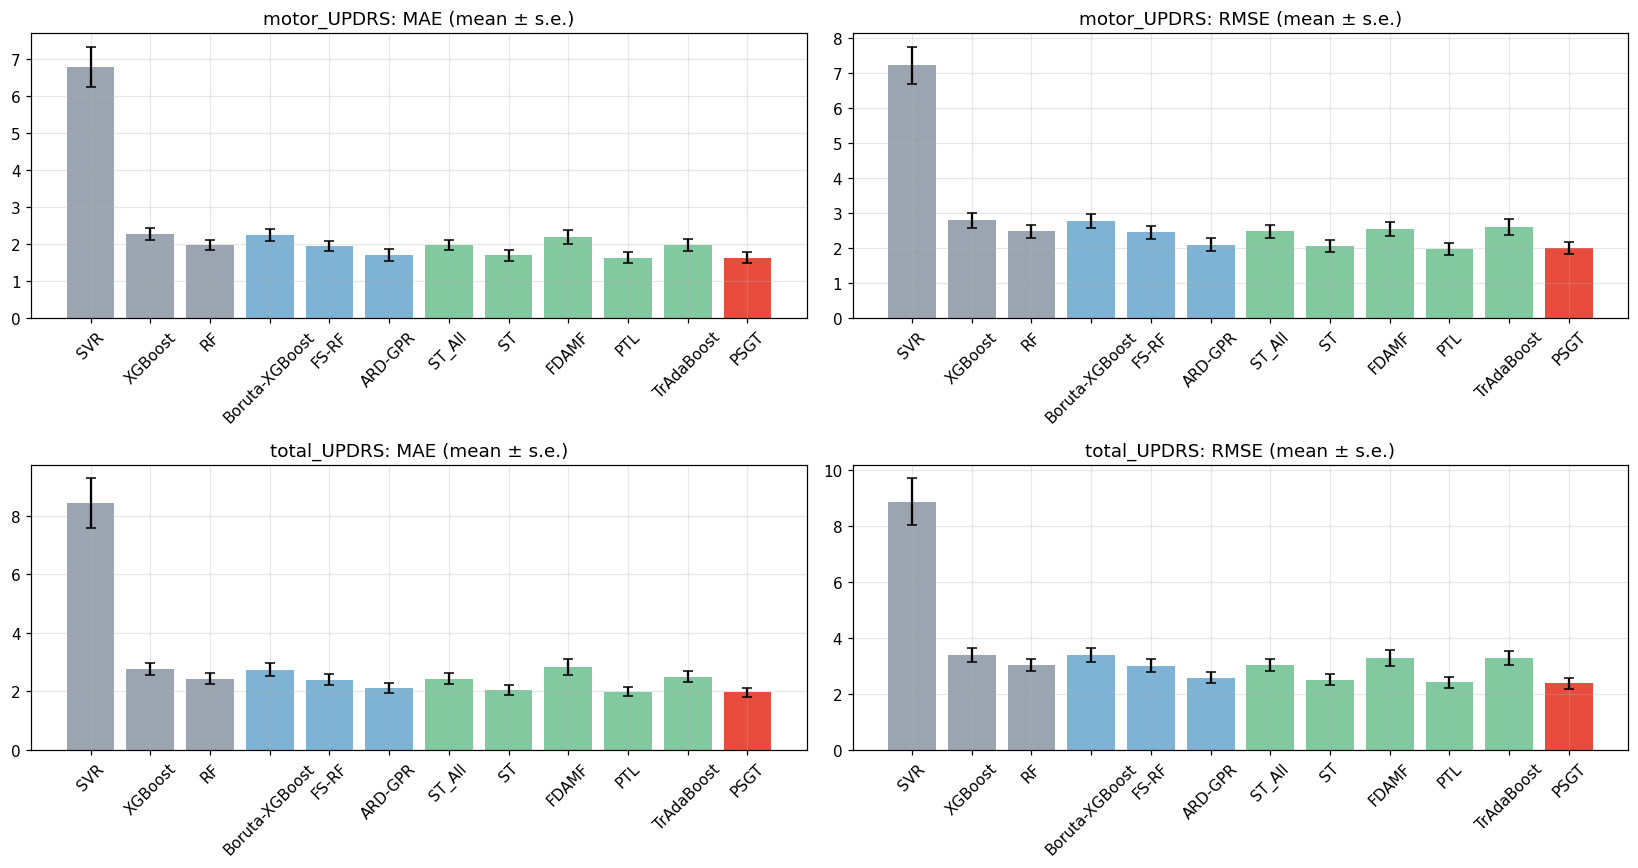

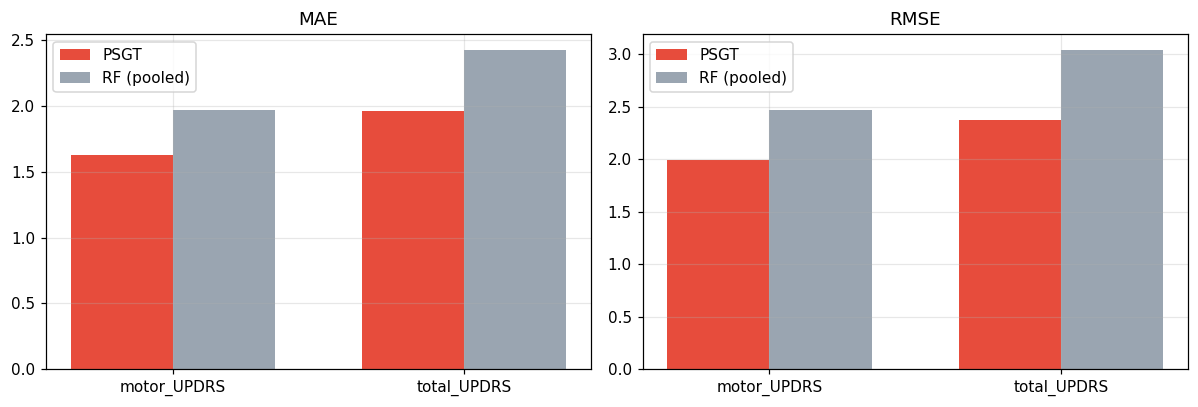

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15, 8))
colors = {'Single':'#9aa5b1','Combined':'#7fb3d5','Transfer':'#82c9a0','Proposed':'#e74c3c'}
for r, target in enumerate(TARGETS):
    for c, met in enumerate(['MAE', 'RMSE']):
        v = per_patient(target, met)[ORDER[:-1]]; ax = axs[r, c]
        ax.bar(v.columns, v.mean(), yerr=v.std()/np.sqrt(len(v)), color=[colors[GROUP[m]] for m in v.columns], capsize=3)
        ax.set_title(f'{target}: {met} (mean ± s.e.)'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_method_comparison.png'); plt.show()

# PSGT vs the Random-Forest baseline (same two metrics as the review slide)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, met in enumerate(['MAE', 'RMSE']):
    w = .35; x = np.arange(2)
    ax[i].bar(x - w/2, [per_patient(t, met)['PSGT'].mean() for t in TARGETS], w, label='PSGT', color='#e74c3c')
    ax[i].bar(x + w/2, [per_patient(t, met)['RF'].mean() for t in TARGETS], w, label='RF (pooled)', color='#9aa5b1')
    ax[i].set_xticks(x); ax[i].set_xticklabels(TARGETS); ax[i].set_title(met); ax[i].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_psgt_vs_rf.png'); plt.show()

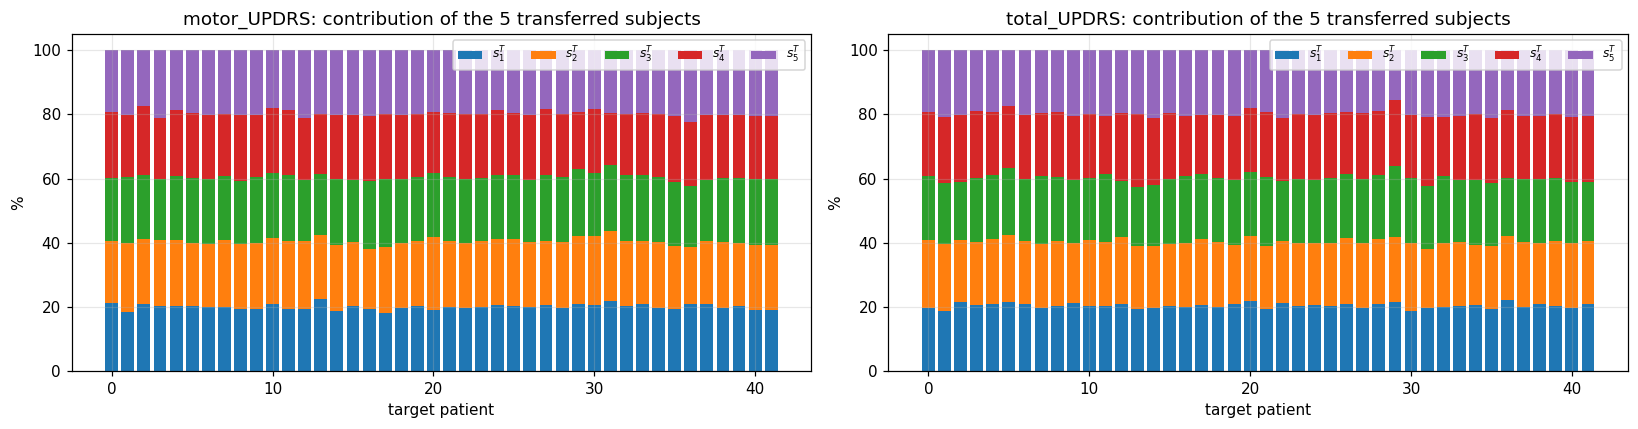

Average number of instances transferred by PSGT: {'motor_UPDRS': np.float64(10.6), 'total_UPDRS': np.float64(9.4)}


In [12]:
# Shapley subject-importance per target patient (paper Fig. 7)
fig, axs = plt.subplots(1, 2, figsize=(15, 4))
for ax, target in zip(axs, TARGETS):
    psi = np.array([r['details']['psi'] for r in RESULTS[target]]) * 100
    bottom = np.zeros(len(psi))
    for j in range(psi.shape[1]):
        ax.bar(range(len(psi)), psi[:, j], bottom=bottom, label=f'$s_{j+1}^T$'); bottom += psi[:, j]
    ax.set_title(f'{target}: contribution of the 5 transferred subjects'); ax.set_xlabel('target patient'); ax.set_ylabel('%'); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_subject_shapley.png'); plt.show()
nt = {t: np.mean([r['details']['n_transferred'] for r in RESULTS[t]]) for t in TARGETS}
print('Average number of instances transferred by PSGT:', {k: round(v, 1) for k, v in nt.items()})

### 8.2 Wilcoxon signed-rank test (PSGT vs every other method, paired by patient on MAE) - paper Table 4

In [13]:
def wilcoxon_table():
    rows = {}
    for target in TARGETS:
        mae = per_patient(target, 'MAE'); rows[target] = {}
        for m in ORDER[:-1]:
            if m == 'PSGT': continue
            d = mae['PSGT'] - mae[m]
            rows[target][m] = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
    t = pd.DataFrame(rows); t['sig. (motor)'] = t['motor_UPDRS'] < 0.05; t['sig. (total)'] = t['total_UPDRS'] < 0.05
    return t
WT = wilcoxon_table()
display(WT.style.format({'motor_UPDRS': '{:.2e}', 'total_UPDRS': '{:.2e}'}))
print('p < 0.05  ->  the PSGT error distribution differs significantly from that method.')

,motor_UPDRS,total_UPDRS,sig. (motor),sig. (total)
SVR,4.55e-13,4.55e-13,True,True
XGBoost,1.69e-10,4.86e-10,True,True
RF,1.63e-07,5.71e-07,True,True
Boruta-XGBoost,6.37e-12,5.73e-10,True,True
FS-RF,4.11e-05,1.79e-06,True,True
ARD-GPR,2.95e-02,5.86e-04,True,True
ST_All,1.63e-07,5.71e-07,True,True
ST,3.18e-03,7.09e-03,True,True
FDAMF,5.54e-06,7.11e-08,True,True
PTL,9.46e-01,1.35e-01,False,False


p < 0.05  ->  the PSGT error distribution differs significantly from that method.


### 8.3 PSGT sensitivity analysis (number of transferred subjects k, transfer ratio 1/L, train-validation-test split)
Run on the first `SENS_PATIENTS` target patients to keep runtime manageable (motor-UPDRS; change `SENS_TARGET` for total).

Sensitivity to k ...
  k = 1: MAE 1.411
  k = 3: MAE 1.469
  k = 5: MAE 1.414
  k = 7: MAE 1.464
  k = 10: MAE 1.397
Sensitivity to L ...
  L = 3: MAE 1.474
  L = 5: MAE 1.414
  L = 6: MAE 1.412
  L = 8: MAE 1.466
  L = 10: MAE 1.466
Sensitivity to train:val:test ...
  ratio = (1, 1, 8): MAE 1.600
  ratio = (2, 2, 6): MAE 1.556
  ratio = (3, 3, 4): MAE 1.470
  ratio = (6, 2, 2): MAE 1.414
sensitivity done in 8.5 min


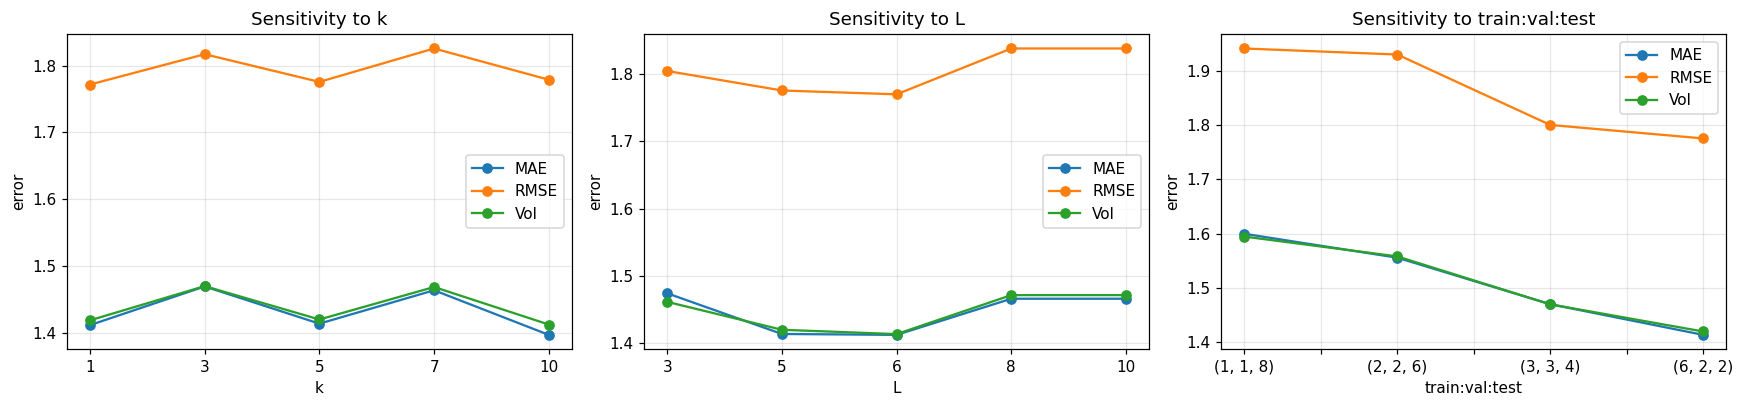

\n--- k ---


,MAE,RMSE,Vol
1,1.411,1.772,1.419
3,1.469,1.817,1.470
5,1.414,1.776,1.420
7,1.464,1.826,1.468
10,1.397,1.779,1.412


\n--- L ---


,MAE,RMSE,Vol
3,1.474,1.805,1.461
5,1.414,1.776,1.420
6,1.412,1.770,1.413
8,1.466,1.838,1.471
10,1.466,1.838,1.471


\n--- train:val:test ---


,MAE,RMSE,Vol
"(1, 1, 8)",1.600,1.941,1.595
"(2, 2, 6)",1.556,1.930,1.558
"(3, 3, 4)",1.470,1.800,1.470
"(6, 2, 2)",1.414,1.776,1.420


In [14]:
# ===================== 8.3 PSGT sensitivity analysis (fast + robust version) =====================
# Needs the cells above to have been run once (imports, config, data, helpers, section 5).
from IPython.display import display
_needed = ['DATA', 'FEATS', 'SUBJECTS', 'PARAMS', 'K', 'SPLIT', 'SEED', 'OUT_DIR', 'N_JOBS',
           'make_rf', 'metrics', 'patient_arrays', 'rank_sources', 'train_source_models']
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f'Run the cells above first (missing: {_missing})'

SENS_TARGET   = 'motor_UPDRS'
SENS_PATIENTS = 6      # target patients used here (increase for a smoother curve, e.g. 10)
SENS_COAL     = 15     # Monte-Carlo coalitions per transferred subject (main run uses 40)
SENS_PERM     = 12     # permutations used for subject-Shapley when k is large

def psgt_sens_one(t, target, SM, ntree, L, k, ratio, n_coal=SENS_COAL, n_perm=SENS_PERM, inst_ntree=10, seed=SEED):
    """One PSGT run for patient t -> metrics dict. Same algorithm as psgt_predict, but the subject-level Shapley value
    is EXACT only for k <= 6 (2^k coalitions) and permutation-sampled for larger k (exact k=10/15 would need 1,024 / 32,768 model fits)."""
    rng = np.random.RandomState(seed + int(t))
    Xtr, ytr, Xva, yva, Xte, yte = patient_arrays(t, target, ratio, seed)
    ranking, _ = rank_sources(t, SM, Xva, yva); top = ranking[:k]
    cache = {}
    def gamma(C):                                              # payoff = validation MAE of RF(train U coalition)
        C = tuple(sorted(C))
        if C not in cache:
            if len(C) == 0: X, y = Xtr, ytr
            else:
                X = np.vstack([Xtr] + [DATA[top[i]][FEATS].values for i in C])
                y = np.concatenate([ytr] + [DATA[top[i]][target].values for i in C])
            cache[C] = float(np.mean(np.abs(make_rf(10, seed).fit(X, y).predict(Xva) - yva)))
        return cache[C]
    phi = np.zeros(k)
    if k <= 6:                                                 # exact Shapley (Eq. 7-8)
        for i in range(k):
            rest = [j for j in range(k) if j != i]
            for r in range(k):
                w = factorial(r) * factorial(k - r - 1) / factorial(k)
                for C in combinations(rest, r):
                    phi[i] += w * (gamma(C + (i,)) - gamma(C))
    else:                                                      # permutation-sampling approximation
        for _ in range(n_perm):
            perm = rng.permutation(k); cur = ()
            for i in perm:
                nxt = cur + (i,); phi[i] += (gamma(nxt) - gamma(cur)) / n_perm; cur = nxt
    pp = 1.0 - 1.0 / (1.0 + np.exp(-phi)); psi = pp / pp.sum()            # Eq. 9-10
    nums = np.maximum(1, np.round(psi * int(len(ytr) // L)).astype(int))  # Eq. 11 with N/L cap
    base = gamma(()); selX, selY = [], []
    for i, s in enumerate(top):                                # simplified instance Shapley (Eq. 14)
        Xs, ys = DATA[s][FEATS].values, DATA[s][target].values; m = len(ys)
        acc, cnt = np.zeros(m), np.zeros(m)
        for _ in range(n_coal):
            sz = rng.randint(1, max(2, m // 2) + 1); idx = rng.choice(m, sz, replace=False)
            e = float(np.mean(np.abs(make_rf(inst_ntree, seed).fit(np.vstack([Xtr, Xs[idx]]), np.concatenate([ytr, ys[idx]])).predict(Xva) - yva)))
            acc[idx] += (e - base) / (sz + 1); cnt[idx] += 1
        phi_x = np.where(cnt > 0, acc / np.maximum(cnt, 1), 0.0)
        keep = [j for j in np.argsort(phi_x) if phi_x[j] < 0][:nums[i]]
        selX.append(Xs[keep]); selY.append(ys[keep])
    pred = make_rf(ntree, seed).fit(np.vstack([Xtr] + selX), np.concatenate([ytr] + selY)).predict(Xte)
    return metrics(yte, pred)

def sens_run(param, values):
    P = PARAMS[SENS_TARGET]; out = {}
    for v in values:
        k = v if param == 'k' else K
        L = v if param == 'L' else P['L']
        ratio = v if param == 'ratio' else SPLIT
        res = Parallel(n_jobs=N_JOBS)(delayed(psgt_sens_one)(t, SENS_TARGET, SM_SENS, P['ntree'], L, k, ratio)
                                      for t in SUBJECTS[:SENS_PATIENTS])
        out[str(v)] = pd.DataFrame(res).mean()[['MAE', 'RMSE', 'Vol']]
        print(f'  {param} = {v}: MAE {out[str(v)]["MAE"]:.3f}', flush=True)
    return pd.DataFrame(out).T

if RUN_SENSITIVITY:
    t0 = time.time(); SM_SENS = train_source_models(SENS_TARGET)
    SENS = {}
    for name, param, vals in [('k', 'k', [1, 3, 5, 7, 10]),
                              ('L', 'L', [3, 5, 6, 8, 10]),
                              ('train:val:test', 'ratio', [(1,1,8), (2,2,6), (3,3,4), (6,2,2)])]:
        print(f'Sensitivity to {name} ...'); SENS[name] = sens_run(param, vals)
    print(f'sensitivity done in {(time.time()-t0)/60:.1f} min')
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
    for ax, (name, tab) in zip(axs, SENS.items()):
        tab.plot(marker='o', ax=ax); ax.set_title(f'Sensitivity to {name}'); ax.set_xlabel(name); ax.set_ylabel('error')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_sensitivity.png'); plt.show()
    for name, tab in SENS.items(): print(f'\\n--- {name} ---'); display(tab.round(3))

## 9. NOVELTY - Clinical Severity Category from the PSGT prediction
**Idea (from the review PPT):** after PSGT predicts a continuous Motor- or Total-UPDRS score, convert it into an understandable severity label **Normal / Mild / Moderate / Severe** so that the output is directly interpretable by clinicians and patients, in addition to the numeric score.

**What this section adds**
1. A reusable `severity_category()` mapper with editable thresholds.
2. Evaluation of the category prediction (accuracy, macro-F1, quadratic-weighted κ, within-one-class accuracy, confusion matrix) on all test recordings of all target patients.
3. A **borderline flag**: if the predicted score lies within ±(patient's MAE) of a cut-off, the report says the category is borderline - this turns the model's error bar into clinically honest output.
4. A patient-level report that can be shown during the viva.

> ⚠ **Threshold note (please confirm with your guide / cite in the report).** The telemonitoring dataset uses the *original* UPDRS (Motor 0-108, Total 0-176). The widely-cited severity bands of Martínez-Martín et al. (2015, *Mov Disord*) are defined for MDS-UPDRS Part III (0-132): mild ≤ 32, moderate 33-58, severe ≥ 59. Here those bands are **proportionally rescaled** to the 0-108 / 0-176 scales, and a "Normal / minimal" band below ≈ 10 % of the scale is added. These are *adapted* cut-offs, so call them "literature-adapted", not "clinically validated". A second, data-driven mode (quartiles of the dataset) is also provided so all four classes are populated. The model is research software and not a diagnostic tool.

In [15]:
LABELS = ['Normal', 'Mild', 'Moderate', 'Severe']
SCALE_MAX = {'motor_UPDRS': 108, 'total_UPDRS': 176}
def clinical_cutoffs(target):
    mx = SCALE_MAX[target]
    return [10/108*mx, 32.5/132*mx, 58.5/132*mx]          # Normal|Mild , Mild|Moderate , Moderate|Severe   (rescaled)
def quantile_cutoffs(target):
    return list(np.percentile(df[target], [25, 50, 75]))   # data-driven: quartiles of the whole dataset
CUTOFFS = {'clinical': {t: clinical_cutoffs(t) for t in TARGETS}, 'quantile': {t: quantile_cutoffs(t) for t in TARGETS}}
for mode in CUTOFFS: print(mode, {t: [round(c, 1) for c in v] for t, v in CUTOFFS[mode].items()})

def severity_category(score, target, mode='clinical'):
    """Map a (predicted) UPDRS score to Normal / Mild / Moderate / Severe."""
    cuts = CUTOFFS[mode][target]
    return np.digitize(np.asarray(score, dtype=float), cuts)      # 0..3

def severity_label(score, target, mode='clinical', margin=0.0):
    c = int(severity_category(score, target, mode)); cuts = CUTOFFS[mode][target]
    border = any(abs(float(score) - ct) <= margin for ct in cuts)
    return LABELS[c] + (' (borderline)' if border else '')

clinical {'motor_UPDRS': [10.0, 26.6, 47.9], 'total_UPDRS': [16.3, 43.3, 78.0]}
quantile {'motor_UPDRS': [np.float64(15.0), np.float64(20.9), np.float64(27.6)], 'total_UPDRS': [np.float64(21.4), np.float64(27.6), np.float64(36.4)]}


In [16]:
def category_eval(target, mode):
    yt = np.concatenate([r['y_true'] for r in RESULTS[target]]); yp = np.concatenate([r['preds']['PSGT'] for r in RESULTS[target]])
    ct, cp = severity_category(yt, target, mode), severity_category(yp, target, mode)
    return yt, yp, ct, cp

summ = []
for mode in ['clinical', 'quantile']:
    for target in TARGETS:
        yt, yp, ct, cp = category_eval(target, mode)
        summ.append(dict(mode=mode, target=target, accuracy=accuracy_score(ct, cp), macro_F1=f1_score(ct, cp, average='macro'),
                         within_one_class=np.mean(np.abs(ct - cp) <= 1), quad_weighted_kappa=cohen_kappa_score(ct, cp, weights='quadratic'),
                         classes_present=len(np.unique(ct))))
display(pd.DataFrame(summ).round(3).set_index(['mode', 'target']))

accuracy  macro_F1  within_one_class  \
mode     target                                              
clinical motor_UPDRS     0.887     0.871             1.000   
         total_UPDRS     0.915     0.837             1.000   
quantile motor_UPDRS     0.820     0.820             1.000   
         total_UPDRS     0.835     0.835             0.998   

                      quad_weighted_kappa  classes_present  
mode     target                                             
clinical motor_UPDRS                0.827                3  
         total_UPDRS                0.782                3  
quantile motor_UPDRS                0.928                4  
         total_UPDRS                0.931                4

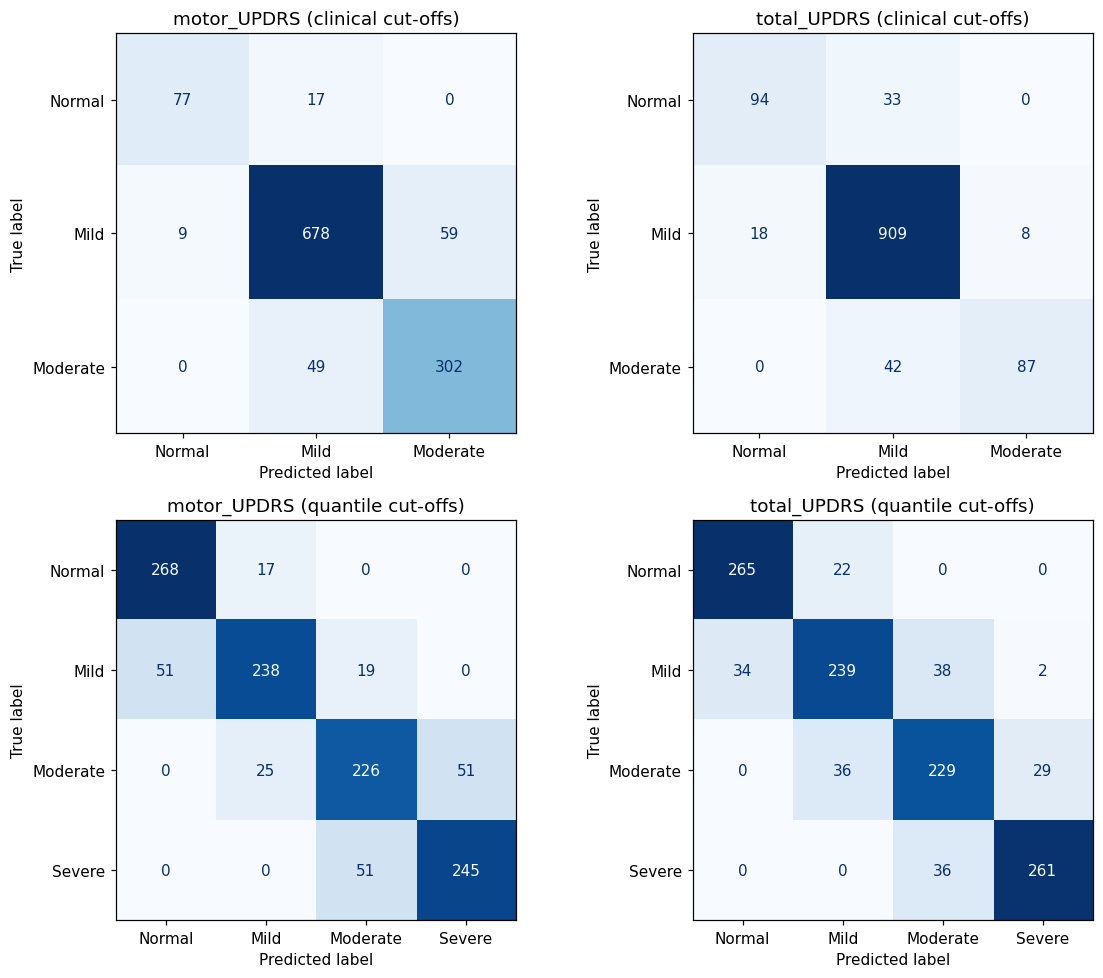

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
for i, mode in enumerate(['clinical', 'quantile']):
    for j, target in enumerate(TARGETS):
        yt, yp, ct, cp = category_eval(target, mode)
        labs = [l for k_, l in enumerate(LABELS) if k_ in set(ct) | set(cp)]; ids = [k_ for k_ in range(4) if k_ in set(ct) | set(cp)]
        ConfusionMatrixDisplay(confusion_matrix(ct, cp, labels=ids), display_labels=labs).plot(ax=axs[i, j], cmap='Blues', colorbar=False)
        axs[i, j].set_title(f'{target} ({mode} cut-offs)'); axs[i, j].grid(False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/fig_severity_confusion.png'); plt.show()

In [18]:
# ---- patient-level severity report (end product of the novelty) ----
MODE = 'clinical'      # or 'quantile'
def patient_report(mode=MODE):
    rows = []
    for rm, rt in zip(RESULTS['motor_UPDRS'], RESULTS['total_UPDRS']):
        mae_m = rm['metrics']['PSGT']['MAE']; mae_t = rt['metrics']['PSGT']['MAE']
        pm, pt = rm['preds']['PSGT'].mean(), rt['preds']['PSGT'].mean()      # mean predicted score over the patient's test recordings
        am, at = rm['y_true'].mean(), rt['y_true'].mean()
        rows.append({'Patient': rm['subject'],
                     'Pred motor': round(pm, 1), 'Motor category': severity_label(pm, 'motor_UPDRS', mode, mae_m), 'Actual motor category': LABELS[int(severity_category(am, 'motor_UPDRS', mode))],
                     'Pred total': round(pt, 1), 'Total category': severity_label(pt, 'total_UPDRS', mode, mae_t), 'Actual total category': LABELS[int(severity_category(at, 'total_UPDRS', mode))]})
    return pd.DataFrame(rows).set_index('Patient')
REPORT = patient_report(); display(REPORT.head(15))

# single-recording demo, like it would be shown to a clinician
r0 = RESULTS['motor_UPDRS'][0]; y0, p0 = r0['y_true'][0], r0['preds']['PSGT'][0]
print(f"Patient {r0['subject']}: true motor-UPDRS {y0:.1f} -> PSGT prediction {p0:.1f}  =>  {severity_label(p0, 'motor_UPDRS', MODE, r0['metrics']['PSGT']['MAE'])}")

,Pred motor,Motor category,Actual motor category,Pred total,Total category,Actual total category
Patient,,,,,,
1,32.3,Moderate,Moderate,41.5,Mild (borderline),Mild
2,14.1,Mild,Mild,16.5,Mild (borderline),Mild
3,27.7,Moderate,Moderate,33.9,Mild,Mild
4,15.6,Mild,Mild,23.5,Mild,Mild
5,31.5,Moderate,Moderate,41.6,Mild,Mild
6,27.4,Moderate,Moderate,41.4,Mild,Mild
7,16.2,Mild,Mild,23.2,Mild,Mild
8,20.0,Mild,Mild,26.0,Mild,Mild
9,18.5,Mild,Mild,25.3,Mild,Mild


Patient 1: true motor-UPDRS 37.0 -> PSGT prediction 32.9  =>  Moderate


## 10. NEW TEST CASE - predict a new, unseen recording / new patient
**Question this section answers:** *if a new test case is given, will the model run on it?* Yes - use `predict_new_case()`.

PSGT is **patient-specific**: to predict one patient it needs some **labelled recordings of that patient** (to train on and to find the 5 most similar source patients). So there are two ways to give a new test case:

| Mode | What you give | Typical use |
|---|---|---|
| **A. New recording of a patient already in the dataset** | the 18 inputs of the new recording + `patient_id` (1-42) | a patient comes back for another voice test |
| **B. Brand-new patient (not in the dataset)** | the 18 inputs of the new recording + `known_data` = a few labelled recordings (>= 10) of that patient (18 inputs + motor_UPDRS + total_UPDRS) | a new patient with a short history |

The 18 inputs are `age, sex` and the 16 voice (dysphonia) features, in the column names of the dataset (`FEATS`). A brand-new patient with **no** labelled recording cannot be predicted by PSGT (there is nothing to measure similarity with).

For each test case the function runs the full PSGT pipeline (subject transfer, Shapley subject importance, Shapley instance selection, Random Forest) for **motor-UPDRS and total-UPDRS** and also gives the **severity category** (novelty). *Run all cells above first (at least sections 1-5 and section 9).*

In [19]:
# ===================== 10. NEW TEST CASE PREDICTION (function) =====================
_needed = ['DATA', 'FEATS', 'SUBJECTS', 'TARGETS', 'PARAMS', 'K', 'SEED', 'N_COALITIONS', 'make_rf', 'train_source_models', 'severity_label']
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f'Run the cells above first (missing: {_missing})'

SM_CACHE = {}                                   # source-domain RF models are trained once per target and re-used
def get_source_models(target):
    if target not in SM_CACHE: SM_CACHE[target] = train_source_models(target)
    return SM_CACHE[target]

def _psgt_on_arrays(Xtr, ytr, Xva, yva, Xnew, sources, target, SM, ntree, L, k=K, n_coal=N_COALITIONS, inst_ntree=10, seed=SEED):
    """Same algorithm as psgt_predict (section 5), but the labelled data of the target and the new inputs are passed in directly."""
    rng = np.random.RandomState(seed)
    mae = {s: float(np.mean(np.abs(SM[s].predict(Xva) - yva))) for s in sources}
    top = sorted(sources, key=lambda s: mae[s])[:k]; k = len(top)                  # Step 1: subject transfer
    cache = {}
    def gamma(C):                                                                  # payoff = validation MAE of RF(train U coalition)
        C = tuple(sorted(C))
        if C not in cache:
            if len(C) == 0: X, y = Xtr, ytr
            else:
                X = np.vstack([Xtr] + [DATA[top[i]][FEATS].values for i in C]); y = np.concatenate([ytr] + [DATA[top[i]][target].values for i in C])
            cache[C] = float(np.mean(np.abs(make_rf(10, seed).fit(X, y).predict(Xva) - yva)))
        return cache[C]
    phi = np.zeros(k)                                                              # Step 2.1: exact subject Shapley value
    for i in range(k):
        rest = [j for j in range(k) if j != i]
        for r in range(k):
            w = factorial(r) * factorial(k - r - 1) / factorial(k)
            for C in combinations(rest, r): phi[i] += w * (gamma(C + (i,)) - gamma(C))
    pp = 1.0 - 1.0 / (1.0 + np.exp(-phi)); psi = pp / pp.sum()
    nums = np.maximum(1, np.round(psi * int(len(ytr) // L)).astype(int))          # number of instances per transferred patient (cap N/L)
    base = gamma(()); selX, selY = [], []
    for i, s in enumerate(top):                                                    # Step 2.2: simplified instance Shapley value
        Xs, ys = DATA[s][FEATS].values, DATA[s][target].values; m = len(ys); acc, cnt = np.zeros(m), np.zeros(m)
        for _ in range(n_coal):
            sz = rng.randint(1, max(2, m // 2) + 1); idx = rng.choice(m, sz, replace=False)
            e = float(np.mean(np.abs(make_rf(inst_ntree, seed).fit(np.vstack([Xtr, Xs[idx]]), np.concatenate([ytr, ys[idx]])).predict(Xva) - yva)))
            acc[idx] += (e - base) / (sz + 1); cnt[idx] += 1
        phi_x = np.where(cnt > 0, acc / np.maximum(cnt, 1), 0.0)
        keep = [j for j in np.argsort(phi_x) if phi_x[j] < 0][:nums[i]]            # drop harmful (positive-Shapley) instances
        selX.append(Xs[keep]); selY.append(ys[keep])
    pred = make_rf(ntree, seed).fit(np.vstack([Xtr] + selX), np.concatenate([ytr] + selY)).predict(Xnew)   # Step 3
    return pred, dict(top=top, n_transferred=int(sum(len(a) for a in selY)), n_train=len(ytr))

def predict_new_case(new_features, patient_id=None, known_data=None, exclude_sources=(), drop_row=None,
                     true_values=None, mode='clinical', verbose=True):
    """
    new_features    : dict (one recording) or DataFrame (one or more recordings) with the 18 inputs `FEATS`.
    patient_id      : MODE A - id (1-42) of a patient in the dataset; all his/her recordings are the labelled data.
    known_data      : MODE B - DataFrame of a brand-new patient's labelled recordings (FEATS + motor_UPDRS + total_UPDRS, >= 10 rows).
    exclude_sources : patient ids that must not be used as source patients (needed only to simulate a new patient from the dataset).
    drop_row        : (MODE A, testing only) row index of the patient's data to remove, so that this recording is truly unseen.
    true_values     : optional {'motor_UPDRS': value(s), 'total_UPDRS': value(s)} to print the error.
    mode            : severity cut-offs, 'clinical' (literature-adapted) or 'quantile'.
    """
    X_new = pd.DataFrame([new_features] if isinstance(new_features, dict) else new_features)
    miss = [c for c in FEATS if c not in X_new.columns]
    if miss: raise KeyError(f'new_features is missing these inputs: {miss}')
    X_new = X_new[FEATS].values.astype(float)
    if (patient_id is None) == (known_data is None): raise ValueError('give exactly one of patient_id (mode A) or known_data (mode B)')
    rows = []
    for target in TARGETS:
        p = PARAMS[target]
        if patient_id is not None:
            d = DATA[patient_id]; d = d.drop(index=drop_row) if drop_row is not None else d; excl = {patient_id}
        else:
            d = known_data; excl = set(exclude_sources)
        d = d.reset_index(drop=True)
        if len(d) < 10: raise ValueError(f'need at least 10 labelled recordings of the patient, got {len(d)}')
        Xl, yl = d[FEATS].values.astype(float), d[target].values.astype(float)
        tr, va = train_test_split(np.arange(len(d)), test_size=0.25, random_state=SEED)
        sources = [s for s in SUBJECTS if s not in excl]
        pred, info = _psgt_on_arrays(Xl[tr], yl[tr], Xl[va], yl[va], X_new, sources, target, get_source_models(target), p['ntree'], p['L'])
        typ = float(np.mean([r['metrics']['PSGT']['MAE'] for r in RESULTS[target]])) if 'RESULTS' in globals() else 0.0   # typical PSGT error -> borderline flag
        tv = None if true_values is None else np.atleast_1d(true_values[target])
        for j, pr in enumerate(pred):
            row = {'case': j + 1, 'target': target, 'predicted UPDRS': round(float(pr), 2), 'severity': severity_label(pr, target, mode, typ)}
            if tv is not None: row.update({'true UPDRS': round(float(tv[j]), 2), 'abs error': round(abs(float(tv[j]) - float(pr)), 2), 'true severity': severity_label(tv[j], target, mode, 0.0)})
            row.update({'labelled recordings used': len(d), 'similar patients': info['top'], 'instances transferred': info['n_transferred']})
            rows.append(row)
    out = pd.DataFrame(rows)
    if verbose: display(out)
    return out
print('predict_new_case() is ready.')

predict_new_case() is ready.


In [20]:
# ===================== TEST CASE 1 (mode A): a truly unseen recording of patient 8 =====================
# recording number 20 of patient 8 is REMOVED from the labelled data, so the model never sees it.
pid, row = 8, 20
d8 = DATA[pid]
test1 = d8.loc[[row], FEATS]                                   # the new test case = 18 inputs
res1 = predict_new_case(test1, patient_id=pid, drop_row=row, true_values={t: d8.loc[row, t] for t in TARGETS})

# ===================== TEST CASE 2 (mode A): values typed by hand (new voice recording of patient 3) =====================
# Replace the numbers by your own measurements. Keys must be exactly the names in FEATS.
print('Required input names:', FEATS)
# NOTE: these demo numbers were copied from an existing recording of patient 3, so this case only shows the input format.
# Use your own new measurements here.
new_recording = {'age': 57.0, 'sex': 0, 'Jitter(%)': 0.0029, 'Jitter(Abs)': 2e-05, 'Jitter:RAP': 0.00112, 'Jitter:PPQ5': 0.00168, 'Jitter:DDP': 0.00337,
                 'Shimmer': 0.00745, 'Shimmer(dB)': 0.087, 'Shimmer:APQ3': 0.00318, 'Shimmer:APQ5': 0.00377, 'Shimmer:APQ11': 0.00612, 'Shimmer:DDA': 0.00955,
                 'NHR': 0.009395, 'HNR': 28.466, 'RPDE': 0.37566, 'DFA': 0.58972, 'PPE': 0.14911}
res2 = predict_new_case(new_recording, patient_id=3)

# ===================== TEST CASE 3 (mode B): a brand-new patient =====================
# Simulation: patient 5 is treated as a NEW patient - only his first 25 recordings are known (with labels),
# patient 5 is excluded from the source patients, and recording 30 is the unseen test case.
src_pid, n_known = 5, 25
known = DATA[src_pid].iloc[:n_known]                           # FEATS + motor_UPDRS + total_UPDRS of the new patient
test3 = DATA[src_pid].loc[[30], FEATS]
res3 = predict_new_case(test3, known_data=known, exclude_sources=[src_pid], true_values={t: DATA[src_pid].loc[30, t] for t in TARGETS})

,case,target,predicted UPDRS,severity,true UPDRS,abs error,true severity,labelled recordings used,similar patients,instances transferred
0,1,motor_UPDRS,20.53,Mild,21.79,1.26,Mild,149,"[38, 9, 11, 19, 12]",18
1,1,total_UPDRS,27.35,Mild,27.79,0.44,Mild,149,"[19, 40, 23, 9, 12]",20


Required input names: ['age', 'sex', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP', 'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']


,case,target,predicted UPDRS,severity,labelled recordings used,similar patients,instances transferred
0,1,motor_UPDRS,28.38,Moderate,144,"[34, 6, 39, 33, 17]",15
1,1,total_UPDRS,36.96,Mild,144,"[34, 42, 29, 17, 28]",19


,case,target,predicted UPDRS,severity,true UPDRS,abs error,true severity,labelled recordings used,similar patients,instances transferred
0,1,motor_UPDRS,31.72,Moderate,31.00,0.72,Moderate,25,"[1, 39, 28, 21, 41]",3
1,1,total_UPDRS,41.68,Mild (borderline),41.75,0.07,Mild,25,"[1, 41, 6, 39, 21]",1


In [21]:
# ===================== YOUR OWN TEST CASE FROM CSV FILES (remove the leading # to use) =====================
# my_known = pd.read_csv('new_patient_labelled.csv')   # columns: age, sex, <16 voice features>, motor_UPDRS, total_UPDRS  (>= 10 rows)
# my_new   = pd.read_csv('new_recordings.csv')         # columns: age, sex, <16 voice features>  (one or more rows)
# predict_new_case(my_new, known_data=my_known)                      # brand-new patient  (mode B)
# predict_new_case(my_new, patient_id=12)                            # patient 12 of the dataset (mode A)

## 11. Save outputs
Everything is written to `outputs/` (and zipped for download from Colab).

In [22]:
for target in TARGETS:
    summary(target).to_csv(f'{OUT_DIR}/table_{target}_summary.csv')
    compare(target).to_csv(f'{OUT_DIR}/table_{target}_vs_paper.csv')
    per_patient(target, 'MAE').to_csv(f'{OUT_DIR}/per_patient_MAE_{target}.csv')
WT.to_csv(f'{OUT_DIR}/wilcoxon_pvalues.csv'); REPORT.to_csv(f'{OUT_DIR}/patient_severity_report.csv')
import shutil; shutil.make_archive('psgt_outputs', 'zip', OUT_DIR)
try:
    from google.colab import files; files.download('psgt_outputs.zip')
except Exception: print('Saved: psgt_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
* The complete pipeline of the base paper - subject transfer, Shapley-based subject importance, simplified Shapley instance selection with the N/L transfer cap and an RF predictor - is implemented and evaluated on all 42 patients for Motor- and Total-UPDRS.
* All 11 comparison models of the paper's Table 3 are implemented (SVR, XGBoost, RF, Boruta-XGBoost, FS-RF, ARD-GPR, ST-All, ST, FDAMF, PTL, TrAdaBoost) with a Wilcoxon significance test and a sensitivity analysis.
* **Novelty:** PSGT's numeric UPDRS prediction is converted to a Normal / Mild / Moderate / Severe category with a borderline flag, evaluated by accuracy, F1, weighted-κ and confusion matrices.
* **Future work:** adaptive selection of k, MFCC / time-frequency voice features, validated clinical cut-offs for the original UPDRS, external validation.